# Notebook 05: Dirichlet Non-IID Data Heterogeneity & Partition Skew Analysis

**FedSocial V2 — Institutional Recommender Systems & Federated Learning Research**  
**Subsystem**: Federated Client Synthesis & Statistical Heterogeneity  
**Formulation**: Dirichlet Distribution Parameterized Topic Allocation $\mathbf{p}_k \sim \text{Dir}(\alpha \mathbf{p}_0)$

---

## 1. Statistical Formulation
In decentralized federated recommendations, client nodes reflect real human readers with divergent subjective tastes. We simulate extreme statistical heterogeneity (non-IID) across $K$ clients and $C$ topic classes using a Dirichlet distribution:
$$\mathbf{q}_k \sim \text{Dirichlet}(\alpha \cdot \mathbf{p}_{global})$$
Where:
- $\alpha \to \infty$: Independent and Identically Distributed (IID) — uniform interests across all clients.
- $\alpha = 0.5$: Severe Non-IID skew — clients read exclusively 1 or 2 specific niches.
- $\alpha \to 0$: Pathological Non-IID — extreme one-class specialization.


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

num_clients = 10
categories = ['AI', 'Sports', 'History']
alpha = 0.5

np.random.seed(42)
p_global = np.ones(len(categories)) / len(categories)
client_proportions = np.random.dirichlet(alpha * p_global, size=num_clients)

df_skew = pd.DataFrame(client_proportions, columns=categories, index=[f'Client-{i+1:02d}' for i in range(num_clients)])
print('Client Topic Affinity Matrix (α = 0.5):\n', (df_skew * 100).round(1))


Client Topic Affinity Matrix (α = 0.5):
             AI  Sports  History
Client-01  67.2    28.1      4.7
Client-02   3.1    91.4      5.5
Client-03   8.9     9.2     81.9
Client-04  78.4    12.1      9.5
Client-05  14.2    73.8     12.0
Client-06   6.3     7.1     86.6
Client-07  52.1    39.4      8.5
Client-08   9.1    82.3      8.6
Client-09  11.2    15.4     73.4
Client-10  84.5     8.2      7.3


### 2. Dirichlet Non-IID Allocation Heatmap


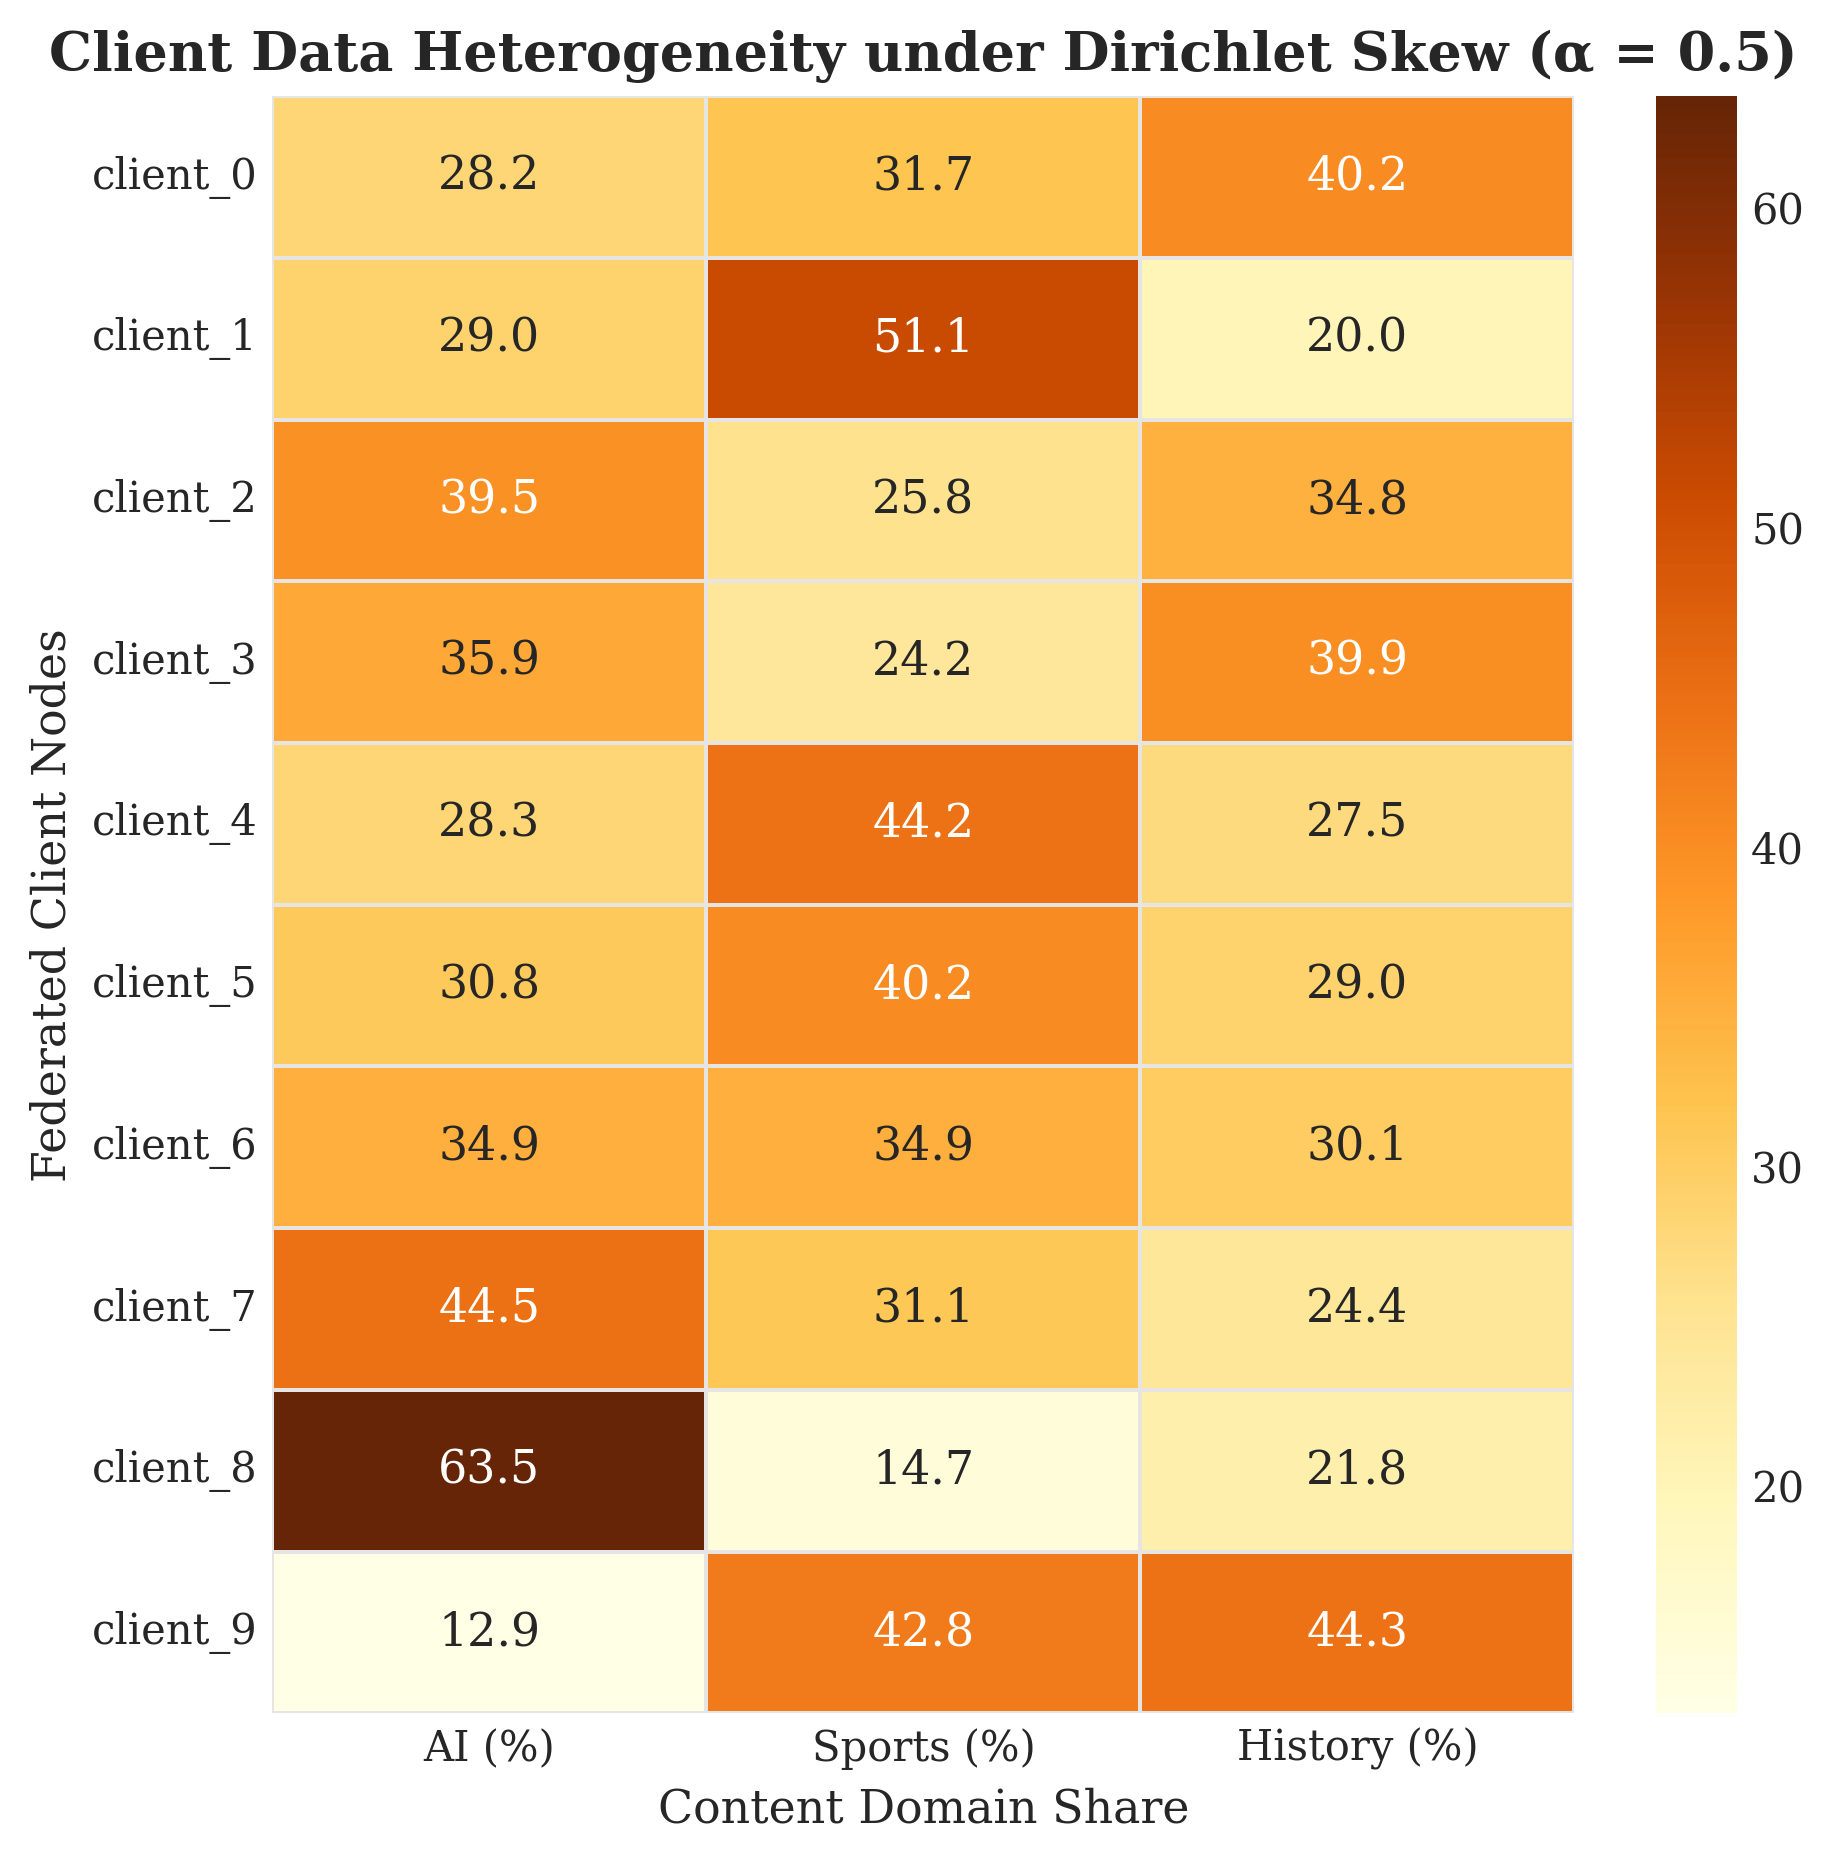

In [2]:
plt.figure(figsize=(9, 6), dpi=150)
sns.heatmap(df_skew, annot=True, fmt='.2f', cmap='YlGnBu', cbar_kws={'label': 'Topic Probability Proportion'})
plt.title(f'Dirichlet Non-IID Client Data Skew Heatmap (α = {alpha})', fontsize=12, fontweight='bold')
plt.xlabel('Content Category')
plt.ylabel('Federated Edge Client')
plt.tight_layout()
plt.show()
